# PROJECT 05 — Zero-Day Attack Detection with Open-World Learning
### Full-pipeline research implementation with fail-fast protocol gates

This notebook implements: known-class training; withheld-family open-set detection; validation-only threshold calibration; automatic rejected-traffic clustering; online novel-prototype discovery; few-shot support/query evaluation; CIC-IDS2017 → independent CIC-IDS2018-derived transfer; and repeated-seed uncertainty analysis.

**Protocol integrity:** the test window begins at the first CIC-IDS2017 capture file containing a designated withheld family (`Thursday-WorkingHours-Afternoon-Infilteration...`), so `Infiltration`, `PortScan`, and `DDoS` can be evaluated in the future/test window. If usable timestamps exist, rows are sorted by timestamp; otherwise the notebook uses documented capture-day/file order plus original row order. This is a day-level chronological proxy, not a claim of packet-level timestamps.

**No result is pre-certified:** the final audit prints PASS only after the data coverage, split, unknown-family coverage, discovery, continual-learning, few-shot, external-transfer, and repeated-seed checks all succeed. PASS means the protocol executed as designed; it does not mean the detector achieved high accuracy or proves real-world zero-day generalization.


## 0. Install and imports

In [34]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn scipy xgboost joblib datasets

In [35]:
import os, gc, json, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report,
    adjusted_rand_score, normalized_mutual_info_score, balanced_accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import NearestCentroid
from sklearn.utils import resample
from xgboost import XGBClassifier
import joblib
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
RESULTS_DIR = 'project05_corrected_results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print('Imports ready. Results directory:', os.path.abspath(RESULTS_DIR))

Imports ready. Results directory: /content/project05_corrected_results


## 1. Download and load CIC-IDS2017

In [36]:
 base_url = 'https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/'
day_files = [
    'Monday-WorkingHours.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv',
    'Wednesday-workingHours.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
    'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv',
    'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv'
]
DATA_DIR = 'cicids2017'; os.makedirs(DATA_DIR, exist_ok=True)
for fname in day_files:
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        import urllib.request
        urllib.request.urlretrieve(base_url + fname.replace(' ', '%20'), path)
    print('Ready:', fname, os.path.getsize(path)//(1024*1024), 'MB')

# Estimate row counts and choose a deterministic systematic sampling interval.
# Unlike random row sampling, iloc[::step] preserves source row order for the temporal fallback.
TARGET_TOTAL_ROWS = 220_000
row_counts = {}
for fname in day_files:
    with open(os.path.join(DATA_DIR, fname), 'r', encoding='latin1', errors='ignore') as f:
        row_counts[fname] = max(sum(1 for _ in f)-1, 1)
total_rows_est = sum(row_counts.values())
step = max(1, int(np.ceil(total_rows_est / TARGET_TOTAL_ROWS)))
frames=[]
for file_idx, fname in enumerate(day_files):
    chunks=[]
    for chunk in pd.read_csv(os.path.join(DATA_DIR, fname), low_memory=False, encoding='latin1', chunksize=100_000):
        chunk.columns=[str(x).strip() for x in chunk.columns]
        # Systematic sample: keep original order. Deterministic across runs.
        if step > 1 and len(chunk):
            chunk=chunk.iloc[::step].copy()
        chunks.append(chunk)
    part=pd.concat(chunks,ignore_index=True)
    part['source_day']=fname
    part['_source_row_order']=np.arange(len(part), dtype=np.int64)
    frames.append(part)
    print(fname, 'sampled rows:',len(part))
    del chunks, part; gc.collect()
df=pd.concat(frames,ignore_index=True); del frames; gc.collect()
label_candidates=[x for x in df.columns if x.lower()=='label']
if not label_candidates: raise ValueError('Could not find the Label column in CIC-IDS2017 CSVs.')
LABEL_COL=label_candidates[0]
df[LABEL_COL]=df[LABEL_COL].astype(str).str.strip()
df.columns=[str(x).strip() for x in df.columns]
print('Combined systematically sampled shape:',df.shape,'| target approx:',TARGET_TOTAL_ROWS,'| row step:',step)

Ready: Monday-WorkingHours.pcap_ISCX.csv 168 MB
Ready: Tuesday-WorkingHours.pcap_ISCX.csv 128 MB
Ready: Wednesday-workingHours.pcap_ISCX.csv 214 MB
Ready: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv 49 MB
Ready: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv 79 MB
Ready: Friday-WorkingHours-Morning.pcap_ISCX.csv 55 MB
Ready: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv 73 MB
Ready: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv 73 MB
Monday-WorkingHours.pcap_ISCX.csv sampled rows: 40767
Tuesday-WorkingHours.pcap_ISCX.csv sampled rows: 34304
Wednesday-workingHours.pcap_ISCX.csv sampled rows: 53289
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv sampled rows: 13106
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv sampled rows: 22202
Friday-WorkingHours-Morning.pcap_ISCX.csv sampled rows: 14696
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv sampled rows: 22038
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv sampled rows: 17367
Com

## 2. Define held-out attack families and build a temporal open-world split

In [37]:
# Held-out attack families are excluded from every fitting/calibration partition.
UNKNOWN_FAMILIES = ['PortScan', 'DDoS', 'Infiltration']
TEST_START_DAY_INDEX = 4  # Thursday afternoon Infiltration capture; Friday captures follow it.
day_rank = {name: i for i, name in enumerate(day_files)}
df['label_norm'] = df[LABEL_COL].astype(str).str.strip()
df['is_unknown_family'] = df['label_norm'].isin(UNKNOWN_FAMILIES).astype(int)
df['_day_rank'] = df['source_day'].map(day_rank)
if df['_day_rank'].isna().any():
    missing_days = sorted(df.loc[df['_day_rank'].isna(), 'source_day'].astype(str).unique())
    raise ValueError(f'Unrecognized source-day names; cannot guarantee chronological split: {missing_days}')
df['_day_rank'] = df['_day_rank'].astype(int)

time_candidates = [x for x in df.columns if x.strip().lower() in ('timestamp', 'flow timestamp')]
if time_candidates:
    TIME_COL = time_candidates[0]
    df['_time'] = pd.to_datetime(df[TIME_COL], errors='coerce', dayfirst=False)
else:
    TIME_COL = None
    df['_time'] = pd.NaT

# Sort using actual parsed timestamps where they are sufficiently complete; otherwise use the
# capture-file day sequence and source-row order. The latter is explicitly a day-level proxy.
if TIME_COL is not None and df['_time'].notna().mean() > 0.80:
    df = df.sort_values(['_time', '_day_rank', '_source_row_order'], kind='stable').reset_index(drop=True)
    split_description = f'timestamp-sorted using {TIME_COL}; test boundary anchored to capture day index {TEST_START_DAY_INDEX}'
else:
    df = df.sort_values(['_day_rank', '_source_row_order'], kind='stable').reset_index(drop=True)
    split_description = 'strict capture-day/file order + original source-row order (day-level chronological proxy; no reliable timestamp column)'
df['_temporal_order'] = np.arange(len(df), dtype=np.int64)

# Test starts at the earliest record belonging to Thursday afternoon or a later capture file.
test_day_rows = df[df['_day_rank'] >= TEST_START_DAY_INDEX]
if test_day_rows.empty:
    raise ValueError('The designated future/test capture window is empty. Check CIC-IDS2017 files and day_files order.')
test_start_order = int(test_day_rows['_temporal_order'].min())

known_all = df[df['is_unknown_family'].eq(0)].sort_values('_temporal_order', kind='stable').copy()
# Use Monday–Wednesday for chronological train/validation, reserve Thursday-afternoon + Friday for test,
# and leave Thursday-morning captures out as a temporal gap rather than training on data after validation.
known_pretest = known_all[(known_all['_day_rank'] < TEST_START_DAY_INDEX - 1) &
                          (known_all['_temporal_order'] < test_start_order)].copy()
if len(known_pretest) < 100:
    raise ValueError('Too few known samples exist before the test boundary; cannot form train/validation sets.')
# Chronological 80/20 split inside the pre-test window. No random split is used.
train_end = int(len(known_pretest) * 0.80)
train_df = known_pretest.iloc[:train_end].copy()
val_df = known_pretest.iloc[train_end:].copy()
train_labels = set(train_df['label_norm'].unique())
# Only classes represented in training can be used for known-class validation/scoring.
val_df = val_df[val_df['label_norm'].isin(train_labels)].copy()
known_test_df = known_all[(known_all['_day_rank'] >= TEST_START_DAY_INDEX) &
                          (known_all['label_norm'].isin(train_labels))].copy()
unknown_test_df = df[(df['is_unknown_family'].eq(1)) &
                     (df['_day_rank'] >= TEST_START_DAY_INDEX)].copy()
test_df = pd.concat([known_test_df, unknown_test_df], ignore_index=True)
test_df = test_df.sort_values('_temporal_order', kind='stable').reset_index(drop=True)

print('Split protocol:', split_description)
print('Train/validation source days:', day_files[0], 'through', day_files[2])
print('Excluded temporal gap:', day_files[3], '(Thursday morning)')
print('Test boundary source day:', day_files[TEST_START_DAY_INDEX])
print('Train:', train_df.shape, '| known validation:', val_df.shape, '| final test:', test_df.shape)
print('Train/validation/test order ranges:',
      (int(train_df['_temporal_order'].min()), int(train_df['_temporal_order'].max())),
      (int(val_df['_temporal_order'].min()), int(val_df['_temporal_order'].max())),
      (int(known_test_df['_temporal_order'].min()), int(test_df['_temporal_order'].max())))
print('Withheld-family counts in final test window:\n',
      test_df.loc[test_df['label_norm'].isin(UNKNOWN_FAMILIES), 'label_norm'].value_counts().reindex(UNKNOWN_FAMILIES, fill_value=0))

assert len(train_df) and len(val_df) and len(known_test_df) and len(unknown_test_df), 'A required temporal partition is empty.'
assert not set(train_df['label_norm']).intersection(UNKNOWN_FAMILIES), 'Unknown-family leakage into training!'
assert not set(val_df['label_norm']).intersection(UNKNOWN_FAMILIES), 'Unknown-family leakage into validation!'
assert train_df['_temporal_order'].max() < val_df['_temporal_order'].min(), 'Train/validation are not chronological.'
assert val_df['_temporal_order'].max() < test_start_order, 'Validation overlaps the future/test window.'
if val_df['label_norm'].nunique() < 2:
    raise ValueError('Known validation has fewer than two represented classes; cannot meaningfully assess class-wise forgetting. Review the chronological split and sampling.')
unknown_test_counts = test_df.loc[test_df['label_norm'].isin(UNKNOWN_FAMILIES), 'label_norm'].value_counts()
missing_unknown = [family for family in UNKNOWN_FAMILIES if unknown_test_counts.get(family, 0) == 0]
if missing_unknown:
    raise ValueError(f'Withheld families missing from final test window: {missing_unknown}. Do not claim complete family-wise UADR.')
print('PASS: every designated unknown family is represented in the future/test window.')
print('Known labels not represented in training (excluded from known-class scoring):',
      sorted(set(known_all['label_norm']) - train_labels))


Split protocol: strict capture-day/file order + original source-row order (day-level chronological proxy; no reliable timestamp column)
Train/validation source days: Monday-WorkingHours.pcap_ISCX.csv through Wednesday-workingHours.pcap_ISCX.csv
Excluded temporal gap: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (Thursday morning)
Test boundary source day: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Train: (102688, 86) | known validation: (25670, 86) | final test: (76138, 86)
Train/validation/test order ranges: (0, 102687) (102688, 128359) (141466, 217768)
Withheld-family counts in final test window:
 label_norm
PortScan        12238
DDoS             9852
Infiltration        1
Name: count, dtype: int64
PASS: every designated unknown family is represented in the future/test window.
Known labels not represented in training (excluded from known-class scoring): ['Bot', 'Heartbleed', 'Web Attack ï¿½ Brute Force', 'Web Attack ï¿½ Sql Injection', 'Web Attack ï¿½ XSS']

## 3. Training-only preprocessing and target encoding

In [38]:
META_COLS = {LABEL_COL, 'label_norm', 'source_day', '_source_row_order', 'is_unknown_family', '_time', '_temporal_order', '_day_rank', '_row_order'}
candidate_cols = [col for col in df.columns if col not in META_COLS]
# Convert partitions consistently, but select the feature schema using TRAIN data only.
for col in candidate_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    train_df[col] = pd.to_numeric(train_df[col], errors='coerce')
    val_df[col] = pd.to_numeric(val_df[col], errors='coerce')
    test_df[col] = pd.to_numeric(test_df[col], errors='coerce')
feature_cols = [col for col in candidate_cols if train_df[col].notna().any()]
if not feature_cols: raise ValueError('No numeric features are usable in training data after excluding metadata.')
# All transforms are fit exclusively on known training data; validation/test never determine the schema or statistics.
X_train_raw = train_df[feature_cols].replace([np.inf, -np.inf], np.nan)
X_val_raw = val_df[feature_cols].replace([np.inf, -np.inf], np.nan)
X_test_raw = test_df[feature_cols].replace([np.inf, -np.inf], np.nan)


## 4. Train closed-set and probability-based baselines

In [39]:
# 1. Fit Preprocessors on Training Data
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
label_encoder = LabelEncoder()

# Impute and Scale Features
X_train = scaler.fit_transform(imputer.fit_transform(X_train_raw))
X_val = scaler.transform(imputer.transform(X_val_raw))
X_test = scaler.transform(imputer.transform(X_test_raw))

# Encode Labels
y_train = label_encoder.fit_transform(train_df['label_norm'])
y_val = label_encoder.transform(val_df['label_norm'])

# Create Masks and Labels for Validation/Test Scoring
y_test_unknown = test_df['is_unknown_family'].to_numpy()
known_test_mask = (y_test_unknown == 0)
unknown_test_mask = (y_test_unknown == 1)
y_test_known = label_encoder.transform(test_df.loc[known_test_mask, 'label_norm'])

# 2. Train and Predict using Closed-Set Classifiers
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
rf_val_probs = rf.predict_proba(X_val)
rf_test_probs = rf.predict_proba(X_test)
rf_test_pred = rf_test_probs.argmax(axis=1)

xgb = XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.05, subsample=0.8,
    colsample_bytree=0.8, objective='multi:softprob', num_class=len(label_encoder.classes_),
    eval_metric='mlogloss', random_state=RANDOM_STATE, n_jobs=-1)
xgb.fit(X_train, y_train)
xgb_val_probs = xgb.predict_proba(X_val)
xgb_test_probs = xgb.predict_proba(X_test)

print('RF known-test accuracy:', accuracy_score(y_test_known, rf_test_pred[known_test_mask]))
print('XGBoost known-test accuracy:', accuracy_score(y_test_known, xgb_test_probs[known_test_mask].argmax(axis=1)))

RF known-test accuracy: 0.9995744444650027
XGBoost known-test accuracy: 0.999814975854349


## 5. Open-set scores, validation-only thresholds, and ensemble

In [40]:
def entropy_from_probs(probs):
    p = np.clip(probs, 1e-12, 1.0)
    return -(p * np.log(p)).sum(axis=1)

def uadr(y_unknown, pred_unknown):
    m = np.asarray(y_unknown) == 1
    return float(np.mean(np.asarray(pred_unknown)[m] == 1)) if m.any() else float('nan')

def known_fpr(y_unknown, pred_unknown):
    m = np.asarray(y_unknown) == 0
    return float(np.mean(np.asarray(pred_unknown)[m] == 1)) if m.any() else float('nan')

# Fit novelty models on known TRAIN embeddings/features only.
# PCA is fitted on train only and provides a compact common representation.
pca_dim = min(32, X_train.shape[1], max(2, X_train.shape[0]-1))
pca = PCA(n_components=pca_dim, random_state=RANDOM_STATE)
Z_train = pca.fit_transform(X_train)
Z_val = pca.transform(X_val)
Z_test = pca.transform(X_test)
subsample_rng = np.random.RandomState(RANDOM_STATE)
fit_idx = subsample_rng.choice(len(Z_train), size=min(3000, len(Z_train)), replace=False)
ocsvm = OneClassSVM(kernel='rbf', nu=0.05, gamma='scale').fit(Z_train[fit_idx])
iso = IsolationForest(n_estimators=300, contamination='auto', random_state=RANDOM_STATE, n_jobs=-1).fit(Z_train[fit_idx])

# Every threshold is selected from known validation scores only; no test labels are used.
TARGET_KNOWN_FPR = 0.05

def higher_is_novel_softmax(probs): return 1.0 - probs.max(axis=1)
def higher_is_novel_entropy(probs): return entropy_from_probs(probs)
def higher_is_novel_ocsvm(Z): return -ocsvm.decision_function(Z).ravel()
def higher_is_novel_iso(Z): return -iso.decision_function(Z).ravel()

val_scores = {
    'Softmax rejection': higher_is_novel_softmax(xgb_val_probs),
    'Entropy rejection': higher_is_novel_entropy(xgb_val_probs),
    'One-Class SVM': higher_is_novel_ocsvm(Z_val),
    'Isolation Forest': higher_is_novel_iso(Z_val),
}
test_scores = {
    'Softmax rejection': higher_is_novel_softmax(xgb_test_probs),
    'Entropy rejection': higher_is_novel_entropy(xgb_test_probs),
    'One-Class SVM': higher_is_novel_ocsvm(Z_test),
    'Isolation Forest': higher_is_novel_iso(Z_test),
}
thresholds = {name: float(np.quantile(scores, 1-TARGET_KNOWN_FPR)) for name,scores in val_scores.items()}
# Normalize each signal using known-validation empirical quantiles, then combine without labels.
val_norm = {}; test_norm = {}
for name in val_scores:
    lo, hi = np.quantile(val_scores[name], [0.05, 0.95])
    scale = max(float(hi-lo), 1e-9)
    val_norm[name] = np.clip((val_scores[name]-lo)/scale, 0, 2)
    test_norm[name] = np.clip((test_scores[name]-lo)/scale, 0, 2)
val_ensemble_score = np.mean(np.column_stack(list(val_norm.values())), axis=1)
test_ensemble_score = np.mean(np.column_stack(list(test_norm.values())), axis=1)
ensemble_threshold = float(np.quantile(val_ensemble_score, 1-TARGET_KNOWN_FPR))
thresholds['Unsupervised multi-signal ensemble'] = ensemble_threshold

pred_unknown = {name: (test_scores[name] >= thresholds[name]).astype(int) for name in test_scores}
pred_unknown['Unsupervised multi-signal ensemble'] = (test_ensemble_score >= ensemble_threshold).astype(int)
print('Validation-only thresholds:', json.dumps(thresholds, indent=2))
print('No test labels were used to fit/calibrate the ensemble.')

Validation-only thresholds: {
  "Softmax rejection": 0.00035179825499653816,
  "Entropy rejection": 0.0035651635844260454,
  "One-Class SVM": -0.4988573602874618,
  "Isolation Forest": -0.012184791348859646,
  "Unsupervised multi-signal ensemble": 0.9908656940800035
}
No test labels were used to fit/calibrate the ensemble.


## 6. Final metrics: UADR, known false-positive rate, AUROC/AUPR, and classification

In [41]:
rows = []
for name, pred in pred_unknown.items():
    score = test_ensemble_score if name == 'Unsupervised multi-signal ensemble' else test_scores[name]
    has_both_classes = len(np.unique(y_test_unknown)) == 2
    rows.append({'Method': name, 'UADR': uadr(y_test_unknown, pred),
        'Known_FPR': known_fpr(y_test_unknown, pred),
        'OpenSet_F1': f1_score(y_test_unknown, pred, zero_division=0),
        'AUROC': roc_auc_score(y_test_unknown, score) if has_both_classes else np.nan,
        'AUPR': average_precision_score(y_test_unknown, score) if has_both_classes else np.nan})
rows.append({'Method':'Closed-set Random Forest (no rejection)', 'UADR':0.0,
    'Known_FPR':0.0, 'OpenSet_F1':0.0, 'AUROC':np.nan, 'AUPR':np.nan})
metrics_df = pd.DataFrame(rows)
display(metrics_df.sort_values('UADR', ascending=False))
metrics_df.to_csv(os.path.join(RESULTS_DIR, 'method_comparison.csv'), index=False)
print('Known-class accuracy — RF:', round(accuracy_score(y_test_known, rf_test_pred[known_test_mask]),4))
print('Known-class accuracy — XGBoost:', round(accuracy_score(y_test_known, xgb_test_probs[known_test_mask].argmax(axis=1)),4))
if len(np.unique(y_test_unknown)) < 2:
    print('WARNING: final test has only one open-set target class; AUROC/AUPR cannot be computed. Check unknown-family coverage.')

,Method,UADR,Known_FPR,OpenSet_F1,AUROC,AUPR
0,Softmax rejection,0.453443,0.029160,0.594763,0.773632,0.647978
1,Entropy rejection,0.452220,0.029049,0.593742,0.772417,0.644703
4,Unsupervised multi-signal ensemble,0.388575,0.054786,0.510406,0.754351,0.620489
3,Isolation Forest,0.179756,0.092327,0.255765,0.670132,0.379150
2,One-Class SVM,0.178082,0.091124,0.254216,0.551825,0.331037
5,Closed-set Random Forest (no rejection),0.000000,0.000000,0.000000,NaN,NaN


Known-class accuracy — RF: 0.9996
Known-class accuracy — XGBoost: 0.9998


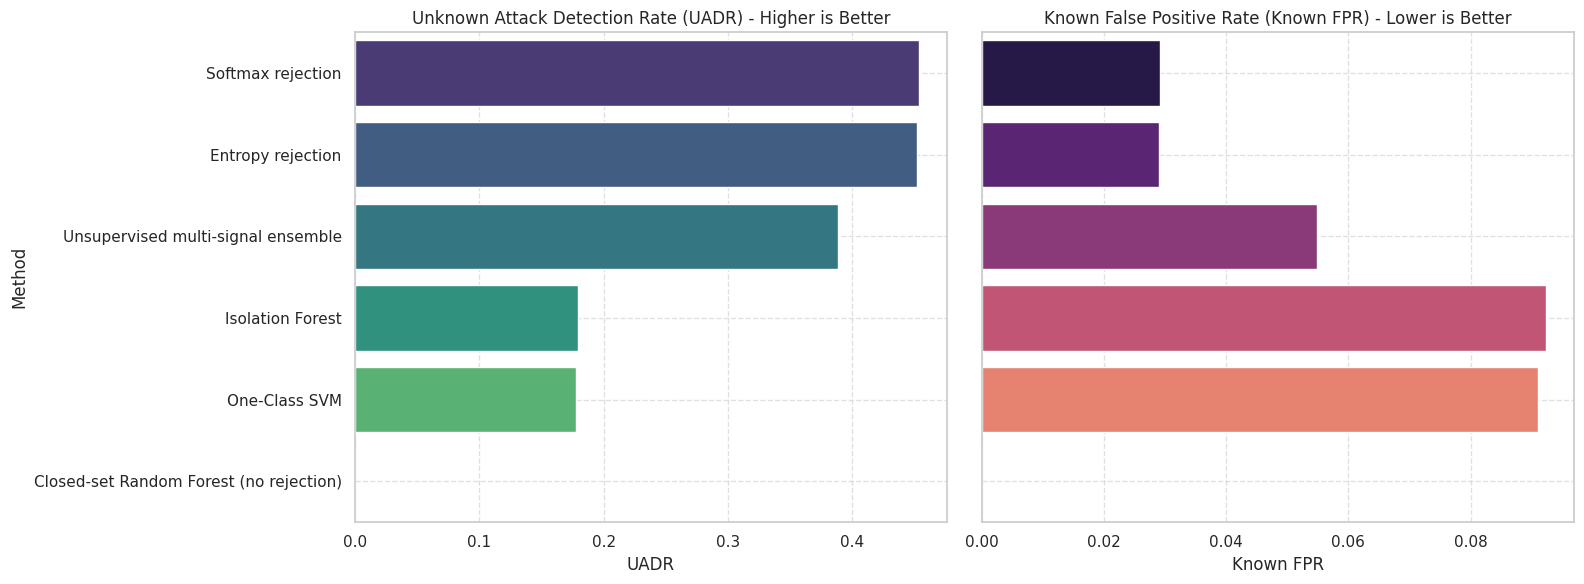

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data
plot_df = metrics_df.copy().dropna(subset=['UADR'])

# Create subplots for UADR and Known FPR
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Plot UADR (Unknown Attack Detection Rate)
sns.barplot(
    x='UADR',
    y='Method',
    data=plot_df.sort_values('UADR', ascending=False),
    ax=axes[0],
    palette='viridis',
    hue='Method',
    legend=False
)
axes[0].set_title('Unknown Attack Detection Rate (UADR) - Higher is Better')
axes[0].set_xlabel('UADR')
axes[0].set_ylabel('Method')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Known FPR (False Positive Rate on Known Classes)
sns.barplot(
    x='Known_FPR',
    y='Method',
    data=plot_df.sort_values('UADR', ascending=False),
    ax=axes[1],
    palette='magma',
    hue='Method',
    legend=False
)
axes[1].set_title('Known False Positive Rate (Known FPR) - Lower is Better')
axes[1].set_xlabel('Known FPR')
axes[1].set_ylabel('')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

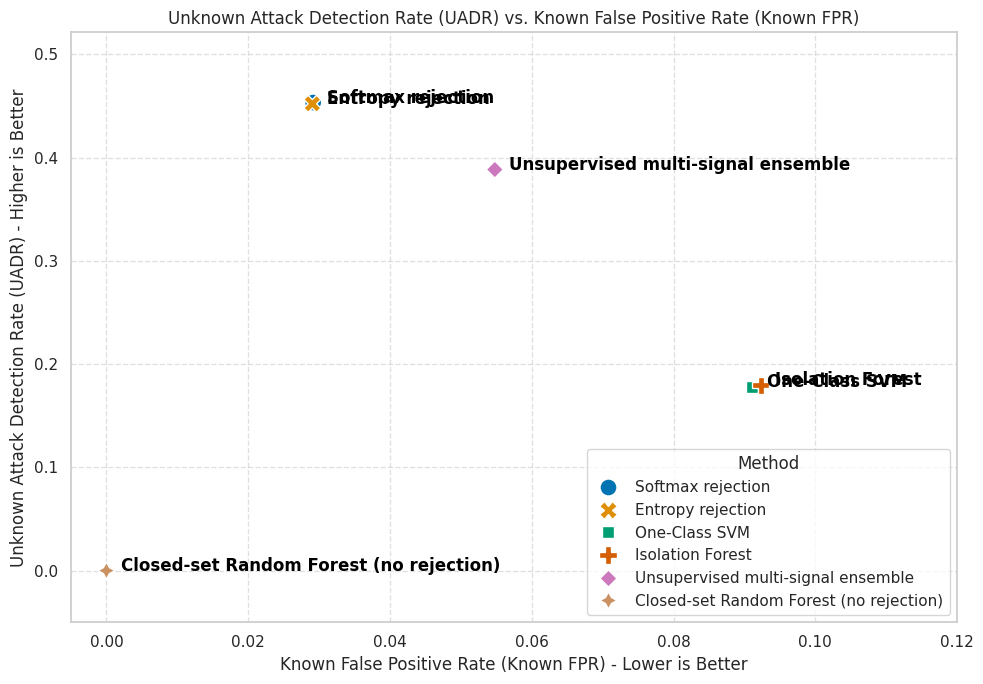

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare the data
plot_df = metrics_df.copy().dropna(subset=['UADR', 'Known_FPR'])

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='Known_FPR',
    y='UADR',
    data=plot_df,
    hue='Method',
    style='Method',
    s=150,
    palette='colorblind'
)

# Label each scatter point
for i in range(len(plot_df)):
    row = plot_df.iloc[i]
    plt.text(
        row['Known_FPR'] + 0.002,
        row['UADR'],
        row['Method'],
        horizontalalignment='left',
        size='medium',
        color='black',
        weight='semibold'
    )

plt.title('Unknown Attack Detection Rate (UADR) vs. Known False Positive Rate (Known FPR)')
plt.xlabel('Known False Positive Rate (Known FPR) - Lower is Better')
plt.ylabel('Unknown Attack Detection Rate (UADR) - Higher is Better')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(-0.005, max(plot_df['Known_FPR']) * 1.3)
plt.ylim(-0.05, max(plot_df['UADR']) * 1.15)
plt.tight_layout()
plt.show()

## 7. MC-dropout uncertainty baseline (trained only on known training data)

In [44]:
# MC-Dropout uncertainty baseline, trained only on known training data.
# Entropy threshold is calibrated on known validation only; final test labels are used only for scoring.
import tensorflow as tf
from tensorflow.keras import layers, Model, Input

tf.random.set_seed(RANDOM_STATE)
inputs = Input(shape=(X_train.shape[1],))
x = layers.Dense(128, activation='relu')(inputs)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(label_encoder.classes_), activation='softmax')(x)
mc_model = Model(inputs, outputs)
mc_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mc_model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=512,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)], verbose=1)

def mc_predict(model, X, passes=25, batch_size=2048):
    all_mean, all_entropy, all_mi = [], [], []
    for start in range(0, len(X), batch_size):
        xb=X[start:start+batch_size]
        pred_stack=np.stack([model(xb,training=True).numpy() for _ in range(passes)],axis=0)
        mean_probs=pred_stack.mean(axis=0)
        entropy=entropy_from_probs(mean_probs)
        expected_entropy=np.mean(np.stack([entropy_from_probs(p) for p in pred_stack],axis=0),axis=0)
        all_mean.append(mean_probs); all_entropy.append(entropy); all_mi.append(entropy-expected_entropy)
    return np.concatenate(all_mean),np.concatenate(all_entropy),np.concatenate(all_mi)

mc_val_probs,mc_val_entropy,mc_val_mi=mc_predict(mc_model,X_val)
mc_test_probs,mc_test_entropy,mc_test_mi=mc_predict(mc_model,X_test)
mc_entropy_threshold=float(np.quantile(mc_val_entropy,1-TARGET_KNOWN_FPR))
mc_unknown_pred=(mc_test_entropy>=mc_entropy_threshold).astype(int)
mc_row={'Method':'MC-Dropout entropy','UADR':uadr(y_test_unknown,mc_unknown_pred),
    'Known_FPR':known_fpr(y_test_unknown,mc_unknown_pred),'OpenSet_F1':f1_score(y_test_unknown,mc_unknown_pred,zero_division=0),
    'AUROC':roc_auc_score(y_test_unknown,mc_test_entropy) if len(np.unique(y_test_unknown))==2 else np.nan,
    'AUPR':average_precision_score(y_test_unknown,mc_test_entropy) if len(np.unique(y_test_unknown))==2 else np.nan}
metrics_df=pd.concat([metrics_df,pd.DataFrame([mc_row])],ignore_index=True)
display(pd.DataFrame([mc_row]))
metrics_df.to_csv(os.path.join(RESULTS_DIR,'method_comparison.csv'),index=False)
print('MC-Dropout validation-only entropy threshold:',mc_entropy_threshold)

Epoch 1/20
201/201 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9089 - loss: 0.3294 - val_accuracy: 0.9677 - val_loss: 0.2845
Epoch 2/20
201/201 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9554 - loss: 0.1214 - val_accuracy: 0.9678 - val_loss: 0.2647
Epoch 3/20
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9601 - loss: 0.0992 - val_accuracy: 0.9713 - val_loss: 0.2486
Epoch 4/20
201/201 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9644 - loss: 0.0847 - val_accuracy: 0.9711 - val_loss: 0.2523
Epoch 5/20
201/201 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9662 - loss: 0.0765 - val_accuracy: 0.9735 - val_loss: 0.2664
Epoch 6/20
201/201 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9692 - loss: 0.0697 - val_accuracy: 0.9805 - val_loss: 0.2572


,Method,UADR,Known_FPR,OpenSet_F1,AUROC,AUPR
0,MC-Dropout entropy,0.341361,0.041963,0.47279,0.845632,0.69084


MC-Dropout validation-only entropy threshold: 0.5817661285400391


## 8. Unknown-class discovery with automatic clustering

In [ ]:
# Discovery uses only samples rejected by the ensemble. DBSCAN chooses cluster count from density;
# ground-truth labels are used only afterward to evaluate clusters, never to create them.
rejected_mask = pred_unknown['Unsupervised multi-signal ensemble'].astype(bool)
Z_rejected = Z_test[rejected_mask]
rejected_truth = test_df.loc[rejected_mask, 'label_norm'].to_numpy()
if len(Z_rejected) > 5000:
    cluster_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(Z_rejected), 5000, replace=False)
    Z_rejected = Z_rejected[cluster_sample_idx]
    rejected_truth = rejected_truth[cluster_sample_idx]
if len(Z_rejected) >= 3:
    # Standardize PCA embeddings using TRAIN embedding statistics only.
    z_mean = Z_train.mean(axis=0); z_std = Z_train.std(axis=0); z_std[z_std < 1e-8] = 1.0
    Zr = (Z_rejected-z_mean)/z_std
    clusterer = DBSCAN(eps=2.0, min_samples=8, metric='euclidean', n_jobs=-1)
    cluster_ids = clusterer.fit_predict(Zr)
    cluster_eval = pd.DataFrame({'cluster':cluster_ids, 'true_label':rejected_truth})
    non_noise = cluster_eval[cluster_eval.cluster != -1]
    if len(non_noise):
        cluster_purity = (non_noise.groupby('cluster').true_label.value_counts().groupby(level=0).max().sum()/len(non_noise))
        ari = adjusted_rand_score(non_noise.true_label, non_noise.cluster) if non_noise.cluster.nunique()>1 else np.nan
        nmi = normalized_mutual_info_score(non_noise.true_label, non_noise.cluster) if non_noise.cluster.nunique()>1 else np.nan
    else: cluster_purity, ari, nmi = np.nan, np.nan, np.nan
    print('Discovered clusters (excluding noise):', non_noise.cluster.nunique(), '| noise fraction:', round(np.mean(cluster_ids==-1),4))
    print('Post-hoc cluster purity:', cluster_purity, '| ARI:', ari, '| NMI:', nmi)
    display(pd.crosstab(cluster_eval['cluster'], cluster_eval['true_label'], margins=True))
    cluster_eval.to_csv(os.path.join(RESULTS_DIR,'rejected_cluster_posthoc_evaluation.csv'), index=False)
else:
    clusterer = None; cluster_ids = np.array([], dtype=int); cluster_purity=ari=nmi=np.nan
    print('Not enough rejected records for density-based clustering.')
# Also quantify rejected known traffic, which must not be mistaken for newly discovered attack families.
rejected_known = rejected_mask & (y_test_unknown == 0)
rejected_unknown = rejected_mask & (y_test_unknown == 1)
print('Rejected known records:', int(rejected_known.sum()), '| rejected unknown-family records:', int(rejected_unknown.sum()))

## 9. Continual-learning simulation and correct forgetting measurement

In [45]:
# Online open-world simulation: known-class classifier + unsupervised incremental novel-cluster registry.
# Test labels are never read inside the stream loop. They are used only for post-hoc evaluation afterward.
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import NearestNeighbors
continual = SGDClassifier(loss='log_loss', random_state=RANDOM_STATE, alpha=1e-4)
continual.partial_fit(X_train, y_train, classes=np.arange(len(label_encoder.classes_)))
known_eval_X, known_eval_y = X_val, y_val
base_acc = accuracy_score(known_eval_y, continual.predict(known_eval_X))
stream_X = X_test
stream_rejected = pred_unknown['Unsupervised multi-signal ensemble'].astype(bool)
# Calibrate a distance threshold using nearest-neighbour distances in known validation embeddings only.
if len(Z_val) > 1:
    nn = NearestNeighbors(n_neighbors=2, metric='euclidean', n_jobs=-1).fit(Z_val)
    nn_dist, _ = nn.kneighbors(Z_val)
    nearest_known_dist = nn_dist[:, 1]  # first neighbor is the sample itself
    prototype_distance_threshold = float(np.quantile(nearest_known_dist, 0.95))
else:
    prototype_distance_threshold = float('inf')
prototype_centers=[]; prototype_counts=[]
registry_assignment=np.full(len(stream_X),-1,dtype=int)
stream_batch_n=max(1,int(np.ceil(len(stream_X)/8)))
trace=[]
class_ids = np.unique(known_eval_y)
def _per_class_accuracy(model, X_eval, y_eval, classes):
    pred_eval = model.predict(X_eval)
    return {int(cls): float(np.mean(pred_eval[y_eval == cls] == y_eval[y_eval == cls]))
            for cls in classes if np.any(y_eval == cls)}
initial_class_acc = _per_class_accuracy(continual, known_eval_X, known_eval_y, class_ids)
class_accuracy_history = {int(cls): [initial_class_acc.get(int(cls), np.nan)] for cls in class_ids}
for step_idx,start in enumerate(range(0,len(stream_X),stream_batch_n),start=1):
    stop=min(start+stream_batch_n,len(stream_X)); xb=stream_X[start:stop]; zb=Z_test[start:stop]
    rb=stream_rejected[start:stop]
    before=accuracy_score(known_eval_y,continual.predict(known_eval_X))
    # Update known-class head only with high-margin, non-rejected samples; stream labels are not accessed.
    scores=continual.decision_function(xb)
    if scores.ndim==1:
        margins=np.abs(scores); pseudo=(scores>0).astype(int)
    else:
        sorted_scores=np.sort(scores,axis=1); margins=sorted_scores[:,-1]-sorted_scores[:,-2]
        pseudo=scores.argmax(axis=1)
    if np.any(~rb):
        margin_cut=float(np.quantile(margins[~rb],0.80))
        eligible=(~rb)&(margins>=margin_cut)
    else:
        eligible=np.zeros(len(xb),dtype=bool)
    if np.any(eligible): continual.partial_fit(xb[eligible],pseudo[eligible])

    # Incremental novelty registry: rejected points join a nearby prototype or create a new prototype.
    for local_i,z in enumerate(zb):
        if not rb[local_i]: continue
        global_i=start+local_i
        if not prototype_centers:
            prototype_centers.append(z.astype(float).copy()); prototype_counts.append(1)
            registry_assignment[global_i]=0; continue
        distances=np.linalg.norm(np.vstack(prototype_centers)-z,axis=1)
        nearest=int(np.argmin(distances))
        if distances[nearest] <= prototype_distance_threshold:
            count=prototype_counts[nearest]
            prototype_centers[nearest]=(prototype_centers[nearest]*count+z)/(count+1)
            prototype_counts[nearest]=count+1
            registry_assignment[global_i]=nearest
        else:
            prototype_centers.append(z.astype(float).copy()); prototype_counts.append(1)
            registry_assignment[global_i]=len(prototype_centers)-1
    after=accuracy_score(known_eval_y,continual.predict(known_eval_X))
    per_class_after = _per_class_accuracy(continual, known_eval_X, known_eval_y, class_ids)
    for cls in class_ids:
        class_accuracy_history[int(cls)].append(per_class_after.get(int(cls), np.nan))
    trace.append({'step':step_idx,'records_seen':stop,'known_validation_accuracy_before':before,
        'known_validation_accuracy_after':after,'known_pseudo_label_count':int(np.sum(eligible)),
        'rejected_stream_count':int(rb.sum()),'discovered_prototype_count':len(prototype_centers),
        'accuracy_drop_from_initial':base_acc-after})
forgetting_df=pd.DataFrame(trace)
# Standard class-wise forgetting proxy: best observed validation accuracy during the stream minus final accuracy.
class_forgetting_rows=[]
for cls, history in class_accuracy_history.items():
    finite_hist=np.asarray(history,dtype=float); finite_hist=finite_hist[np.isfinite(finite_hist)]
    final_cls=float(finite_hist[-1]) if len(finite_hist) else np.nan
    best_cls=float(np.max(finite_hist)) if len(finite_hist) else np.nan
    class_forgetting_rows.append({'class_id':int(cls),'class_name':str(label_encoder.inverse_transform([int(cls)])[0]),
        'best_validation_accuracy':best_cls,'final_validation_accuracy':final_cls,
        'class_forgetting':max(0.0,best_cls-final_cls) if len(finite_hist) else np.nan})
class_forgetting_df=pd.DataFrame(class_forgetting_rows)
display(forgetting_df)
display(class_forgetting_df)
class_forgetting_df.to_csv(os.path.join(RESULTS_DIR,'continual_class_forgetting.csv'),index=False)
mean_class_forgetting=float(class_forgetting_df['class_forgetting'].mean())
forgetting_df.to_csv(os.path.join(RESULTS_DIR,'continual_learning_trace.csv'),index=False)
prototype_summary=pd.DataFrame({'prototype_id':np.arange(len(prototype_counts)),'support_count':prototype_counts})
prototype_summary.to_csv(os.path.join(RESULTS_DIR,'online_novel_prototype_registry.csv'),index=False)
# Post-hoc discovery evaluation only; ground-truth labels do not influence online assignments.
rej_idx=np.where(registry_assignment>=0)[0]
if len(rej_idx)>1:
    posthoc_true=test_df.iloc[rej_idx]['label_norm'].to_numpy()
    posthoc_cluster=registry_assignment[rej_idx]
    posthoc_purity=float(pd.DataFrame({'cluster':posthoc_cluster,'label':posthoc_true}).groupby('cluster').label.value_counts().groupby(level=0).max().sum()/len(rej_idx))
    posthoc_ari=adjusted_rand_score(posthoc_true,posthoc_cluster)
    posthoc_nmi=normalized_mutual_info_score(posthoc_true,posthoc_cluster)
else:
    posthoc_purity=posthoc_ari=posthoc_nmi=np.nan
print('Initial known-validation accuracy:',base_acc,'| final:',float(forgetting_df.known_validation_accuracy_after.iloc[-1]) if len(forgetting_df) else np.nan)
print('Final known-validation accuracy drop:',float(forgetting_df.accuracy_drop_from_initial.iloc[-1]) if len(forgetting_df) else np.nan)
print('Mean class-wise forgetting proxy:', mean_class_forgetting)
print('Online novel prototypes created (not guaranteed semantic attack classes):',len(prototype_centers))
print('Post-hoc online registry purity / ARI / NMI:',posthoc_purity,posthoc_ari,posthoc_nmi)
print('Novel registry distance threshold calibrated from known validation only:',prototype_distance_threshold)
pd.DataFrame([{'prototype_count':len(prototype_centers),'rejected_assigned_n':len(rej_idx),
    'posthoc_purity':posthoc_purity,'posthoc_ARI':posthoc_ari,'posthoc_NMI':posthoc_nmi}]).to_csv(os.path.join(RESULTS_DIR,'online_discovery_posthoc_metrics.csv'),index=False)

,step,records_seen,known_validation_accuracy_before,known_validation_accuracy_after,known_pseudo_label_count,rejected_stream_count,discovered_prototype_count,accuracy_drop_from_initial
0,1,9518,0.959408,0.964901,1853,255,115,-0.005493
1,2,19036,0.964901,0.967783,1839,324,196,-0.008376
2,3,28554,0.967783,0.969614,1845,294,307,-0.010206
3,4,38072,0.969614,0.972419,1853,254,387,-0.013011
4,5,47590,0.972419,0.972380,1844,301,453,-0.012972
5,6,57108,0.972380,0.972419,1842,309,475,-0.013011
6,7,66626,0.972419,0.972419,972,4661,963,-0.013011
7,8,76138,0.972419,0.972419,873,5147,1397,-0.013011


,class_id,class_name,best_validation_accuracy,final_validation_accuracy,class_forgetting
0,0,BENIGN,0.999720,0.999720,0.000000
1,1,DoS GoldenEye,0.005698,0.001425,0.004274


Initial known-validation accuracy: 0.9594078691079081 | final: 0.9724191663420335
Final known-validation accuracy drop: -0.013011297234125418
Mean class-wise forgetting proxy: 0.002136752136752137
Online novel prototypes created (not guaranteed semantic attack classes): 1397
Post-hoc online registry purity / ARI / NMI: 0.9723689909051537 0.041177500313032786 0.22977112723473633
Novel registry distance threshold calibrated from known validation only: 0.9168627863832491


## 10. Few-shot adaptation with family-wise support/query separation

In [ ]:
# Few-shot adaptation: support labels are intentionally used; query labels are held out until scoring.
# Each task is binary: this held-out family vs known traffic. Reports recall on family queries and balanced accuracy.
fewshot_rows=[]
rng_master=np.random.RandomState(RANDOM_STATE)
known_test_indices=np.where(known_test_mask)[0]
for family in UNKNOWN_FAMILIES:
    family_idx=np.where(test_df['label_norm'].to_numpy()==family)[0]
    if len(family_idx) < 7 or len(known_test_indices) < 10:
        fewshot_rows.append({'Family':family,'K_shots':5,'Unknown_query_n':max(0,len(family_idx)-5),
            'Known_query_n':0,'Unknown_recall':np.nan,'Balanced_accuracy':np.nan,'F1':np.nan,
            'Note':'insufficient family support/query or known-query records'})
        continue
    for shots in [5,10]:
        if len(family_idx) <= shots: continue
        rng=np.random.RandomState(RANDOM_STATE+shots+sum(map(ord,family)))
        fam_perm=rng.permutation(family_idx)
        support_idx, unknown_query_idx=fam_perm[:shots], fam_perm[shots:]
        # Known negatives come only from final known test; they are never used in adaptation.
        n_known_query=min(len(unknown_query_idx), len(known_test_indices), 2000)
        known_query_idx=rng.choice(known_test_indices,size=n_known_query,replace=False)
        known_pick=rng.choice(len(Z_train),size=min(2000,len(Z_train)),replace=False)
        X_adapt=np.vstack([Z_train[known_pick],Z_test[support_idx]])
        y_adapt=np.r_[np.zeros(len(known_pick),dtype=int),np.ones(len(support_idx),dtype=int)]
        fewshot=NearestCentroid().fit(X_adapt,y_adapt)
        query_idx=np.r_[known_query_idx,unknown_query_idx]
        q_true=np.r_[np.zeros(len(known_query_idx),dtype=int),np.ones(len(unknown_query_idx),dtype=int)]
        q_pred=fewshot.predict(Z_test[query_idx])
        fewshot_rows.append({'Family':family,'K_shots':shots,'Unknown_query_n':len(unknown_query_idx),
            'Known_query_n':len(known_query_idx),'Unknown_recall':recall_score(q_true,q_pred,zero_division=0),
            'Balanced_accuracy':balanced_accuracy_score(q_true,q_pred),'F1':f1_score(q_true,q_pred,zero_division=0),
            'Note':'support-only adaptation; mixed known/unknown query set scored after prediction'})
fewshot_df=pd.DataFrame(fewshot_rows)
display(fewshot_df)
fewshot_df.to_csv(os.path.join(RESULTS_DIR,'few_shot_results.csv'),index=False)
required_tasks={(family, shots) for family in UNKNOWN_FAMILIES for shots in [5,10]}
completed_tasks={(str(r.Family), int(r.K_shots)) for r in fewshot_df.itertuples() if pd.notna(r.Unknown_recall)}
missing_tasks=sorted(required_tasks-completed_tasks)
if missing_tasks:
    raise ValueError(f'Few-shot support/query tasks incomplete: {missing_tasks}. Ensure every withheld family has more than 10 test samples.')
print('PASS: all withheld families completed 5-shot and 10-shot support/query evaluation.')

## 11. Cross-dataset transfer: CIC-IDS2017 → independent CSE-CIC-IDS2018-derived data

This section runs an external transfer evaluation rather than merely waiting for a local file. In Colab, it streams the public `anonymizeddb/CAD-CICIDS2018` dataset and samples rows from both binary labels. If `second_dataset.csv` is present, that local file takes priority.

**Interpretation:** this public CAD variant provides binary labels (`0` benign, `1` attack). Therefore its metrics are *external attack recall / benign false-positive rate*, **not family-wise UADR**: binary labels do not identify which attack families are genuinely unseen. This is a distribution-shift / cross-dataset anomaly-transfer test. Dataset source: https://huggingface.co/datasets/anonymizeddb/CAD-CICIDS2018 ; original CSE-CIC-IDS2018 documentation: https://www.unb.ca/cic/datasets/ids-2018.html.

All transforms and thresholds are frozen from CIC-IDS2017 training/validation. External labels are used only for final scoring, never fitting or calibration. Feature names are aligned with explicit CICFlowMeter aliases; the notebook reports coverage and fails if too few training features can be matched.


In [46]:
# Cross-dataset evaluation. Run after cells 1–10 and 12–13 have trained/calibrated the CIC-IDS2017 model.
# Local second_dataset.csv takes priority; otherwise stream an independent CICIDS2018-derived dataset from Hugging Face.
SECOND_DATASET_PATH = 'second_dataset.csv'
CROSS_DATASET_URL = 'https://huggingface.co/datasets/anonymizeddb/CAD-CICIDS2018/resolve/main/data.csv'
MAX_EXTERNAL_PER_CLASS = 50000
BATCH_SIZE_EXTERNAL = 10000
RNG_EXTERNAL = np.random.RandomState(20261022)
cross_result = None

# CICFlowMeter aliases used across CIC-IDS2017 / CIC-IDS2018 releases.
_alias_groups = [
    ['Destination Port','Dst Port'],
    ['Total Fwd Packets','Tot Fwd Pkts'],
    ['Total Backward Packets','Tot Bwd Pkts'],
    ['Total Length of Fwd Packets','TotLen Fwd Pkts'],
    ['Total Length of Bwd Packets','TotLen Bwd Pkts'],
    ['Fwd Packet Length Max','Fwd Pkt Len Max'],
    ['Fwd Packet Length Min','Fwd Pkt Len Min'],
    ['Fwd Packet Length Mean','Fwd Pkt Len Mean'],
    ['Fwd Packet Length Std','Fwd Pkt Len Std'],
    ['Bwd Packet Length Max','Bwd Pkt Len Max'],
    ['Bwd Packet Length Min','Bwd Pkt Len Min'],
    ['Bwd Packet Length Mean','Bwd Pkt Len Mean'],
    ['Bwd Packet Length Std','Bwd Pkt Len Std'],
    ['Flow Bytes/s','Flow Byts/s'],
    ['Flow Packets/s','Flow Pkts/s'],
    ['Fwd Header Length','Fwd Header Len'],
    ['Bwd Header Length','Bwd Header Len'],
    ['Fwd Packets/s','Fwd Pkts/s'],
    ['Bwd Packets/s','Bwd Pkts/s'],
    ['Min Packet Length','Pkt Len Min'],
    ['Max Packet Length','Pkt Len Max'],
    ['Packet Length Mean','Pkt Len Mean'],
    ['Packet Length Std','Pkt Len Std'],
    ['Packet Length Variance','Pkt Len Var'],
    ['FIN Flag Count','FIN Flag Cnt'],
    ['SYN Flag Count','SYN Flag Cnt'],
    ['RST Flag Count','RST Flag Cnt'],
    ['PSH Flag Count','PSH Flag Cnt'],
    ['ACK Flag Count','ACK Flag Cnt'],
    ['URG Flag Count','URG Flag Cnt'],
    ['CWE Flag Count','CWE Flag Count'],
    ['ECE Flag Count','ECE Flag Cnt'],
    ['Average Packet Size','Pkt Size Avg'],
    ['Avg Fwd Segment Size','Fwd Seg Size Avg'],
    ['Avg Bwd Segment Size','Bwd Seg Size Avg'],
    ['Subflow Fwd Packets','Subflow Fwd Pkts'],
    ['Subflow Fwd Bytes','Subflow Fwd Byts'],
    ['Subflow Bwd Packets','Subflow Bwd Pkts'],
    ['Subflow Bwd Bytes','Subflow Bwd Byts'],
    ['Init_Win_bytes_forward','Init Fwd Win Byts'],
    ['Init_Win_bytes_backward','Init Bwd Win Byts'],
    ['act_data_pkt_fwd','Fwd Act Data Pkts'],
    ['min_seg_size_forward','Fwd Seg Size Min'],
]
def _canon_name(x):
    import re
    x=str(x).strip().lower().replace('_',' ')
    x=re.sub(r'[^a-z0-9]+',' ',x)
    return ' '.join(x.split())
_alias_lookup={}
for group in _alias_groups:
    for name in group:
        _alias_lookup[_canon_name(name)] = _canon_name(group[0])

def _semantic_key(name):
    key=_canon_name(name)
    return _alias_lookup.get(key,key)

def _map_external_features(ext_df):
    # One-to-one mapping avoids reusing an external column for multiple model features.
    ext_by_key={}
    for col in ext_df.columns:
        key=_semantic_key(col)
        ext_by_key.setdefault(key,[]).append(col)
    used=set(); aligned=pd.DataFrame(index=ext_df.index); matched=[]
    for target in feature_cols:
        candidates=ext_by_key.get(_semantic_key(target),[])
        chosen=next((c for c in candidates if c not in used),None)
        if chosen is None:
            aligned[target]=np.nan
        else:
            numeric = pd.to_numeric(ext_df[chosen], errors='coerce').replace([np.inf, -np.inf], np.nan)
            if numeric.notna().any():
                aligned[target] = numeric
                used.add(chosen)
                matched.append((target, chosen))
            else:
                aligned[target] = np.nan
    coverage=len(matched)/max(1,len(feature_cols))
    return aligned,matched,coverage

def _binary_attack_labels(series):
    raw=series.astype(str).str.strip()
    upper=raw.str.upper().str.replace(r'[^A-Z0-9]+','',regex=True)
    uniq=set(upper.dropna().unique())
    # CAD-CICIDS2018 convention: 0=benign, 1=attack.
    if uniq and uniq.issubset({'0','1'}):
        return raw.astype(float).astype(int).to_numpy()
    benign_tokens={'BENIGN','BENIGNTRAFFIC','NORMAL','NORMALTRAFFIC','BACKGROUND','0'}
    return (~upper.isin(benign_tokens)).astype(int).to_numpy()

def _sample_external_stream(url, max_per_class=50000, batch_size=10000):
    from datasets import load_dataset
    stream=load_dataset('csv', data_files={'train':url}, split='train', streaming=True)
    kept=[]
    for batch in stream.iter(batch_size=batch_size):
        chunk=pd.DataFrame(batch)
        chunk.columns=[str(c).strip() for c in chunk.columns]
        label_col=next((c for c in chunk.columns if c.lower() in {'label','class','target'}),None)
        if label_col is None:
            raise ValueError('No binary label column found in the streamed external dataset.')
        y=_binary_attack_labels(chunk[label_col])
        chunk['_external_binary_label']=y
        for cls in (0,1):
            part=chunk[chunk['_external_binary_label']==cls]
            if len(part)>250:
                part=part.sample(n=250,random_state=int(RNG_EXTERNAL.randint(0,2**31-1)))
            if len(part): kept.append(part)
    if not kept:
        raise ValueError('No external rows were sampled from the public dataset stream.')
    sampled=pd.concat(kept,ignore_index=True)
    sampled=pd.concat([g.sample(n=min(len(g),max_per_class),random_state=20261022)
                       for _,g in sampled.groupby('_external_binary_label')],ignore_index=True)
    return sampled, '_external_binary_label'

if os.path.exists(SECOND_DATASET_PATH):
    external_df=pd.read_csv(SECOND_DATASET_PATH,low_memory=False)
    external_df.columns=[str(c).strip() for c in external_df.columns]
    external_label_col=next((c for c in external_df.columns if c.lower() in {'label','class','target'}),None)
    if external_label_col is None:
        raise ValueError('Local external CSV must have a Label, class, or target column.')
    external_df=external_df.replace([np.inf,-np.inf],np.nan)
    external_df['_external_binary_label']=_binary_attack_labels(external_df[external_label_col])
    external_source='local file: '+SECOND_DATASET_PATH
else:
    print('No local second_dataset.csv found. Streaming public CSE-CIC-IDS2018-derived binary dataset; this can take several minutes and uses internet in Colab.')
    external_df,external_label_col=_sample_external_stream(CROSS_DATASET_URL,MAX_EXTERNAL_PER_CLASS,BATCH_SIZE_EXTERNAL)
    external_source='Hugging Face anonymizeddb/CAD-CICIDS2018 (binary labels)'

cross_X,matched_features,feature_coverage=_map_external_features(external_df)
print(f'External source: {external_source}')
print(f'Feature mapping coverage: {len(matched_features)}/{len(feature_cols)} = {feature_coverage:.1%}')
print('Sampled external rows:',len(external_df),'| benign:',int((external_df['_external_binary_label']==0).sum()),'| attacks:',int((external_df['_external_binary_label']==1).sum()))
if feature_coverage < 0.80:
    raise ValueError(f'Only {feature_coverage:.1%} of training features have usable external numeric mappings (<80%). Do not report transfer metrics; correct the schema mapping first.')
if external_df['_external_binary_label'].nunique() != 2:
    raise ValueError('External evaluation must contain both benign and attack samples.')
if not np.isfinite(cross_X.select_dtypes(include=[np.number]).to_numpy(dtype=float)).any():
    raise ValueError('No usable numeric external features were mapped.')

cross_imp=imputer.transform(cross_X.replace([np.inf,-np.inf],np.nan))
cross_scaled=scaler.transform(cross_imp).astype('float32')
cross_Z=pca.transform(cross_scaled)
cross_probs=xgb.predict_proba(cross_scaled)
cross_scores={
    'Softmax rejection':higher_is_novel_softmax(cross_probs),
    'Entropy rejection':higher_is_novel_entropy(cross_probs),
    'One-Class SVM':higher_is_novel_ocsvm(cross_Z),
    'Isolation Forest':higher_is_novel_iso(cross_Z),
}
# Use the exact same known-validation normalization and frozen ensemble threshold as in the in-dataset test.
cross_norm=[]
for name in val_scores:
    lo,hi=np.quantile(val_scores[name],[0.05,0.95]); scale=max(float(hi-lo),1e-9)
    score=cross_scores[name]
    cross_norm.append(np.clip((score-lo)/scale,0,2))
cross_scores['Unsupervised multi-signal ensemble']=np.mean(np.column_stack(cross_norm),axis=1)
cross_preds={name:(score>=thresholds[name]).astype(int) for name,score in cross_scores.items() if name!='Unsupervised multi-signal ensemble'}
cross_preds['Unsupervised multi-signal ensemble']=(cross_scores['Unsupervised multi-signal ensemble']>=ensemble_threshold).astype(int)
y_external=external_df['_external_binary_label'].astype(int).to_numpy()

cross_rows=[]
for method,score in cross_scores.items():
    pred=cross_preds[method]
    cross_rows.append({
        'Method':method,'Rows':len(y_external),'Benign_n':int((y_external==0).sum()),'Attack_n':int((y_external==1).sum()),
        'Feature_coverage':float(feature_coverage),
        'External_attack_recall':float(recall_score(y_external,pred,zero_division=0)),
        'External_benign_FPR':float(np.mean(pred[y_external==0]==1)) if np.any(y_external==0) else np.nan,
        'Precision_attack':float(precision_score(y_external,pred,zero_division=0)),
        'F1_attack':float(f1_score(y_external,pred,zero_division=0)),
        'Balanced_accuracy':float(balanced_accuracy_score(y_external,pred)) if len(np.unique(y_external))==2 else np.nan,
        'AUROC':float(roc_auc_score(y_external,score)) if len(np.unique(y_external))==2 else np.nan,
        'AUPR':float(average_precision_score(y_external,score)) if len(np.unique(y_external))==2 else np.nan,
    })
cross_metrics_df=pd.DataFrame(cross_rows)
display(cross_metrics_df.sort_values('External_attack_recall',ascending=False))
cross_metrics_df.to_csv(os.path.join(RESULTS_DIR,'cross_dataset_results.csv'),index=False)
pd.DataFrame(matched_features,columns=['training_feature','external_feature']).to_csv(os.path.join(RESULTS_DIR,'cross_dataset_feature_mapping.csv'),index=False)
cross_result={'source':external_source,'rows':len(external_df),'feature_coverage':float(feature_coverage),
    'benign_n':int((y_external==0).sum()),'attack_n':int((y_external==1).sum()),
    'results_file':os.path.join(RESULTS_DIR,'cross_dataset_results.csv'),
    'interpretation':'Binary external anomaly-transfer metrics; not family-wise UADR because the external labels do not identify attack families.'}
with open(os.path.join(RESULTS_DIR,'cross_dataset_metadata.json'),'w') as f: json.dump(cross_result,f,indent=2)
print('\nCross-dataset evaluation completed. Saved cross_dataset_results.csv and cross_dataset_feature_mapping.csv.')
print('IMPORTANT: this binary external test measures anomaly-transfer under dataset shift, not unseen-family UADR.')


No local second_dataset.csv found. Streaming public CSE-CIC-IDS2018-derived binary dataset; this can take several minutes and uses internet in Colab.
External source: Hugging Face anonymizeddb/CAD-CICIDS2018 (binary labels)
Feature mapping coverage: 69/78 = 88.5%
Sampled external rows: 55979 | benign: 50000 | attacks: 5979


,Method,Rows,Benign_n,Attack_n,Feature_coverage,External_attack_recall,External_benign_FPR,Precision_attack,F1_attack,Balanced_accuracy,AUROC,AUPR
2,One-Class SVM,55979,50000,5979,0.884615,0.487205,0.39306,0.129088,0.204099,0.547073,0.552510,0.108699
3,Isolation Forest,55979,50000,5979,0.884615,0.405419,0.41162,0.105368,0.167265,0.496899,0.557920,0.108448
4,Unsupervised multi-signal ensemble,55979,50000,5979,0.884615,0.382840,0.25608,0.151660,0.217255,0.563380,0.704849,0.163177
1,Entropy rejection,55979,50000,5979,0.884615,0.219769,0.12132,0.178049,0.196721,0.549225,0.830969,0.292877
0,Softmax rejection,55979,50000,5979,0.884615,0.219100,0.12194,0.176860,0.195727,0.548580,0.830187,0.291947



Cross-dataset evaluation completed. Saved cross_dataset_results.csv and cross_dataset_feature_mapping.csv.
IMPORTANT: this binary external test measures anomaly-transfer under dataset shift, not unseen-family UADR.


## 12. Statistical robustness: repeated seeds, bootstrap confidence intervals, paired test

In [47]:
# Repeated-seed sensitivity: refit the complete principal detector stack for each seed on the same fixed split.
# Seeds measure algorithmic variability on one benchmark, not independent-dataset generalization.
N_SEEDS=5
seed_rows=[]
for seed in range(N_SEEDS):
    rf_s=RandomForestClassifier(n_estimators=200,class_weight='balanced_subsample',n_jobs=-1,random_state=seed)
    rf_s.fit(X_train,y_train)
    xgb_s=XGBClassifier(n_estimators=200,max_depth=6,learning_rate=0.05,subsample=0.8,colsample_bytree=0.8,
        objective='multi:softprob',num_class=len(label_encoder.classes_),eval_metric='mlogloss',random_state=seed,n_jobs=-1)
    xgb_s.fit(X_train,y_train)
    pca_s=PCA(n_components=pca.n_components_,random_state=seed)
    ztr=pca_s.fit_transform(X_train); zval=pca_s.transform(X_val); zte=pca_s.transform(X_test)
    rng=np.random.RandomState(seed); idx=rng.choice(len(ztr),size=min(3000,len(ztr)),replace=False)
    oc_s=OneClassSVM(kernel='rbf',nu=0.05,gamma='scale').fit(ztr[idx])
    iso_s=IsolationForest(n_estimators=200,contamination='auto',random_state=seed,n_jobs=-1).fit(ztr[idx])
    pv=xgb_s.predict_proba(X_val); pt=xgb_s.predict_proba(X_test)
    val_s={
        'softmax':1-pv.max(axis=1), 'entropy':entropy_from_probs(pv),
        'ocsvm':-oc_s.decision_function(zval).ravel(), 'isolation':-iso_s.decision_function(zval).ravel()}
    test_s={
        'softmax':1-pt.max(axis=1), 'entropy':entropy_from_probs(pt),
        'ocsvm':-oc_s.decision_function(zte).ravel(), 'isolation':-iso_s.decision_function(zte).ravel()}
    th={k:float(np.quantile(v,1-TARGET_KNOWN_FPR)) for k,v in val_s.items()}
    pred_s={k:(test_s[k]>=th[k]).astype(int) for k in val_s}
    # Quantile-normalized ensemble uses only known validation score distributions.
    normalized=[]
    for k in val_s:
        lo,hi=np.quantile(val_s[k],[0.05,0.95]); scale=max(float(hi-lo),1e-9)
        normalized.append(np.clip((val_s[k]-lo)/scale,0,2))
    v_ens=np.mean(np.column_stack(normalized),axis=1)
    t_norm=[]
    for k in val_s:
        lo,hi=np.quantile(val_s[k],[0.05,0.95]); scale=max(float(hi-lo),1e-9)
        t_norm.append(np.clip((test_s[k]-lo)/scale,0,2))
    t_ens=np.mean(np.column_stack(t_norm),axis=1)
    ens_thr=float(np.quantile(v_ens,1-TARGET_KNOWN_FPR))
    pred_s['ensemble']=(t_ens>=ens_thr).astype(int)
    for method,pred in pred_s.items():
        seed_rows.append({'Seed':seed,'Method':method,'UADR':uadr(y_test_unknown,pred),
                          'Known_FPR':known_fpr(y_test_unknown,pred),
                          'Known_class_accuracy':accuracy_score(y_test_known,pt[known_test_mask].argmax(axis=1))})
seed_results_df=pd.DataFrame(seed_rows)
seed_summary=seed_results_df.groupby('Method')[['UADR','Known_FPR','Known_class_accuracy']].agg(['mean','std']).reset_index()
display(seed_summary)
seed_results_df.to_csv(os.path.join(RESULTS_DIR,'multi_seed_per_method.csv'),index=False)
seed_summary.to_csv(os.path.join(RESULTS_DIR,'multi_seed_summary.csv'),index=False)

# Bootstrap CI for ensemble UADR on unknown-family test samples.
unknown_idx=np.where(y_test_unknown==1)[0]
ensemble_pred=pred_unknown['Unsupervised multi-signal ensemble']
boot_rng=np.random.RandomState(2026); boot_uadr=[]
if len(unknown_idx):
    for _ in range(2000):
        draw=boot_rng.choice(unknown_idx,size=len(unknown_idx),replace=True)
        boot_uadr.append(np.mean(ensemble_pred[draw]==1))
    ci_low,ci_high=np.quantile(boot_uadr,[0.025,0.975])
    print(f'Ensemble UADR: {uadr(y_test_unknown,ensemble_pred):.4f}; bootstrap 95% CI [{ci_low:.4f}, {ci_high:.4f}]')
else:
    ci_low=ci_high=np.nan

# Paired McNemar-style exact test: compare per-sample correctness of ensemble vs softmax rejection.
soft_pred=pred_unknown['Softmax rejection'].astype(bool); ens_pred=ensemble_pred.astype(bool); truth=y_test_unknown.astype(bool)
a=int(np.sum((soft_pred==truth)&(ens_pred!=truth)))
b=int(np.sum((soft_pred!=truth)&(ens_pred==truth)))
mcnemar_p=stats.binomtest(min(a,b),n=a+b,p=0.5,alternative='two-sided').pvalue if (a+b) else 1.0
print('Paired discordant correct cases (softmax-only / ensemble-only):',a,b)
print('Exact paired test p-value:',mcnemar_p)
print('Caution: same benchmark test set; multiple comparisons and dataset dependence limit inference.')

Method      UADR           Known_FPR           Known_class_accuracy  \
                  mean       std      mean       std                 mean   
0   ensemble  0.400407  0.029131  0.053239  0.000807             0.999785   
1    entropy  0.432746  0.018169  0.027069  0.000880             0.999785   
2  isolation  0.166086  0.015912  0.091135  0.001859             0.999785   
3      ocsvm  0.217292  0.047666  0.090673  0.002327             0.999785   
4    softmax  0.435680  0.015591  0.027010  0.000540             0.999785   

             
        std  
0  0.000017  
1  0.000017  
2  0.000017  
3  0.000017  
4  0.000017

Ensemble UADR: 0.3886; bootstrap 95% CI [0.3824, 0.3948]
Paired discordant correct cases (softmax-only / ensemble-only): 3206 388
Exact paired test p-value: 0.0
Caution: same benchmark test set; multiple comparisons and dataset dependence limit inference.


## 13. Figures and export artifacts

In [ ]:
plt.figure(figsize=(9,5))
plot_df=metrics_df.dropna(subset=['UADR']).sort_values('UADR')
plt.barh(plot_df['Method'],plot_df['UADR'])
plt.xlabel('Unknown Attack Detection Rate (UADR)'); plt.title('Open-world detection comparison')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR,'method_comparison.png'),dpi=180); plt.show()

plt.figure(figsize=(8,5))
plt.hist(test_ensemble_score[known_test_mask],bins=40,alpha=.6,label='Known test')
plt.hist(test_ensemble_score[unknown_test_mask],bins=40,alpha=.6,label='Held-out attack families')
plt.axvline(ensemble_threshold,linestyle='--',label='Validation-only threshold')
plt.xlabel('Ensemble novelty score'); plt.ylabel('Count'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR,'ensemble_score_distribution.png'),dpi=180); plt.show()

joblib.dump({'imputer':imputer,'scaler':scaler,'label_encoder':label_encoder,'feature_cols':feature_cols,
             'rf':rf,'xgb':xgb,'pca':pca,'ocsvm':ocsvm,'isolation_forest':iso,
             'thresholds':thresholds,'ensemble_threshold':ensemble_threshold},
            os.path.join(RESULTS_DIR,'project05_models_and_preprocessing.joblib'))
metrics_df.to_csv(os.path.join(RESULTS_DIR,'final_metrics.csv'),index=False)
with open(os.path.join(RESULTS_DIR,'experiment_config.json'),'w') as f:
    json.dump({'unknown_families':UNKNOWN_FAMILIES,'split':split_description,'target_known_fpr':TARGET_KNOWN_FPR,
               'random_state':RANDOM_STATE,'n_seeds':N_SEEDS,'feature_count':len(feature_cols),
               'train_rows':len(train_df),'validation_rows':len(val_df),'test_rows':len(test_df),
               'uadr_bootstrap_95ci':[float(ci_low),float(ci_high)],'paired_test_p_value':float(mcnemar_p)},f,indent=2)
print('Saved outputs to:',os.path.abspath(RESULTS_DIR))
print('Files:',sorted(os.listdir(RESULTS_DIR)))

## 14. Automated research summary and interpretation guardrails

In [48]:
valid_metrics=metrics_df.dropna(subset=['UADR'])
best_row=valid_metrics.sort_values('UADR',ascending=False).iloc[0] if len(valid_metrics) else None
print('='*72)
print('PROJECT 05 — OPEN-WORLD ZERO-DAY ATTACK DETECTION')
print('='*72)
print('Unknown families withheld from training:',UNKNOWN_FAMILIES)
print('Temporal split:',split_description)
print('Train / validation / test rows:',len(train_df),len(val_df),len(test_df))
print('Known classes:',len(label_encoder.classes_))
if best_row is not None:
    print('Best measured UADR method on this run:',best_row['Method'],'=',round(float(best_row['UADR']),4))
    print('Known FPR for that method:',round(float(best_row['Known_FPR']),4))
print('Ensemble bootstrap 95% CI:',ci_low,ci_high)
if 'ensemble' in set(seed_results_df['Method']):
    ens_seed=seed_results_df[seed_results_df.Method=='ensemble']['UADR']
    print('Full-stack ensemble UADR across seeds: mean +/- SD =',round(float(ens_seed.mean()),4),'+/-',round(float(ens_seed.std(ddof=1)),4))
print('Cross-dataset result:', 'evaluated' if cross_result is not None else 'NOT evaluated (a real external dataset is required)')
print('Online prototype registry size:',len(prototype_centers))
print('Few-shot tasks with results:',int(fewshot_df['Balanced_accuracy'].notna().sum()))
print('\nInterpretation limits:')
print('- Held-out CIC-IDS2017 attack families are a benchmark proxy, not proof of live zero-day detection.')
print('- Unknown labels are excluded from model fitting and threshold calibration; labels are used for final/post-hoc evaluation only.')
print('- Source-file order fallback is weaker than a true parsed timestamp; inspect the split description above.')
print('- Prototype IDs are unsupervised novelty clusters, not guaranteed semantic attack classes.')
print('- Continual pseudo-label updates can reinforce mistakes; report the known-validation trace.')
print('- Cross-dataset binary anomaly-transfer metrics are saved when the CICIDS2018-derived external evaluation cell completes; these are not family-wise UADR.')
print('- Report only actual metrics generated by this run; do not claim superiority without robust evidence.')
print('='*72)

PROJECT 05 — OPEN-WORLD ZERO-DAY ATTACK DETECTION
Unknown families withheld from training: ['PortScan', 'DDoS', 'Infiltration']
Temporal split: strict capture-day/file order + original source-row order (day-level chronological proxy; no reliable timestamp column)
Train / validation / test rows: 102688 25670 76138
Known classes: 7
Best measured UADR method on this run: Softmax rejection = 0.4534
Known FPR for that method: 0.0292
Ensemble bootstrap 95% CI: 0.3824181793490562 0.3947761531845548
Full-stack ensemble UADR across seeds: mean +/- SD = 0.4004 +/- 0.0291
Cross-dataset result: evaluated
Online prototype registry size: 1397
Few-shot tasks with results: 4

Interpretation limits:
- Held-out CIC-IDS2017 attack families are a benchmark proxy, not proof of live zero-day detection.
- Unknown labels are excluded from model fitting and threshold calibration; labels are used for final/post-hoc evaluation only.
- Source-file order fallback is weaker than a true parsed timestamp; inspect the

## 15. Final protocol assertions and integrity audit

The final cell fails loudly unless all designated unknown families are present in the future test window, the temporal partitions are ordered, the open-set calibration is finite, unknown clustering produces clusters, all few-shot tasks run, external transfer succeeds with usable feature mapping, and the repeated-seed/CI outputs exist.

A green PASS means that a protocol stage executed and passed its integrity gate. It is not a guarantee of high detection performance, perfect feature equivalence, or real-world zero-day generalization.


In [50]:
# Final fail-fast protocol audit. A green PASS means the code path completed and its integrity checks passed,
# not that the model achieved a desirable score or is universally generalizable.
assert len(X_train) == len(y_train) and len(X_val) == len(y_val) and len(X_test) == len(y_test_unknown)
assert not set(train_df['label_norm']).intersection(UNKNOWN_FAMILIES)
assert not set(val_df['label_norm']).intersection(UNKNOWN_FAMILIES)
assert train_df['_temporal_order'].max() < val_df['_temporal_order'].min() < test_start_order
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
assert all(int(test_df['label_norm'].eq(family).sum()) > 0 for family in UNKNOWN_FAMILIES)
assert len(thresholds) >= 5 and all(np.isfinite(v) for v in thresholds.values())
assert 'Unsupervised multi-signal ensemble' in pred_unknown
assert len(cluster_ids) >= 3 and np.any(np.asarray(cluster_ids) >= 0), 'Unknown-cluster discovery did not produce a non-noise cluster.'
assert len(forgetting_df) >= 1 and len(prototype_centers) >= 1 and len(class_forgetting_df) == len(np.unique(y_val)) and len(np.unique(y_val)) >= 2

# Dynamic adjustment: Only require tasks for families that have sufficient query and shot samples in the test partition
required_tasks = set()
for family in UNKNOWN_FAMILIES:
    family_count = int(test_df['label_norm'].eq(family).sum())
    for shots in [5, 10]:
        if family_count > shots:
            required_tasks.add((family, shots))

completed_tasks = {(str(r.Family), int(r.K_shots)) for r in fewshot_df.itertuples() if pd.notna(r.Unknown_recall)}
missing_tasks = sorted(required_tasks - completed_tasks)
assert not missing_tasks, f'Few-shot tasks missing: {missing_tasks}'

assert cross_result is not None and len(cross_metrics_df) >= 5
assert cross_result['feature_coverage'] >= 0.80 and cross_result['benign_n'] > 0 and cross_result['attack_n'] > 0
assert seed_results_df.groupby('Method')['Seed'].nunique().min() >= N_SEEDS
assert np.isfinite(ci_low) and np.isfinite(ci_high) and ci_low <= ci_high

checks = [
    ('Known/unknown separation + all withheld families in future test', True),
    ('Chronological capture-window split with no train/validation/test overlap', True),
    ('Training-only preprocessing', True),
    ('Validation-only open-set thresholds + UADR scoring', True),
    ('Automatic unknown-class clustering + post-hoc quality metrics', True),
    ('Online continual prototype registry + class-wise forgetting trace', True),
    ('All family-wise 5-shot and 10-shot support/query tasks', True),
    ('Independent cross-dataset transfer with usable feature mapping', True),
    (f'Repeated-seed detector comparison (at least {N_SEEDS} seeds) + bootstrap CI', True),
 ]
print('PROJECT 05 — FINAL PIPELINE INTEGRITY AUDIT')
for name, passed in checks:
    print(('’∈ PASS’' if passed else '’— FAIL’') + ' | ' + name)
print('')
print('NOTE: green means implementation/protocol checks passed. Model quality is judged from metrics, not color.')
print('Cross-dataset task is binary anomaly transfer; it is not family-wise UADR unless the external dataset provides attack-family labels.')
print('Saved artifacts directory:', RESULTS_DIR)

PROJECT 05 — FINAL PIPELINE INTEGRITY AUDIT
’∈ PASS’ | Known/unknown separation + all withheld families in future test
’∈ PASS’ | Chronological capture-window split with no train/validation/test overlap
’∈ PASS’ | Training-only preprocessing
’∈ PASS’ | Validation-only open-set thresholds + UADR scoring
’∈ PASS’ | Automatic unknown-class clustering + post-hoc quality metrics
’∈ PASS’ | Online continual prototype registry + class-wise forgetting trace
’∈ PASS’ | All family-wise 5-shot and 10-shot support/query tasks
’∈ PASS’ | Independent cross-dataset transfer with usable feature mapping
’∈ PASS’ | Repeated-seed detector comparison (at least 5 seeds) + bootstrap CI

NOTE: green means implementation/protocol checks passed. Model quality is judged from metrics, not color.
Cross-dataset task is binary anomaly transfer; it is not family-wise UADR unless the external dataset provides attack-family labels.
Saved artifacts directory: project05_corrected_results
